# Experiments

Every training run in `runs/` (one folder per run: `config.yaml`, per-epoch `log.csv`, `summary.json`). All numbers below are accuracies on the same 5,000 held-out training images
(stratified split, never trained on), using the exponential moving average of the weights, with and without
test-time augmentation (TTA). Runs whose name ends in `_full` were retrained on all 50,000 images for Kaggle
and have no validation score.

Groups: `a` = 200-epoch screens of the WRN-28 recipe, `b` = other architectures at 200 epochs, `c`/`s` =
longer schedules and variants, `t` = large teachers (36.5M parameters, not submittable), `k` = knowledge
distillation into the 4.84M-parameter WRN-28, `f` / `*f_full` = all-data retrains for submission.

In [1]:
import os
import sys
from pathlib import Path

for _var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_var, "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display

print(f"torch {torch.__version__}, GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'}")

torch 2.14.1+cu130, GPU: NVIDIA GeForce RTX 5080 Laptop GPU


In [2]:
# Chart style: hairline grid and axes, 2px lines, fixed categorical colour order.
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"], "font.size": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-", "axes.axisbelow": True,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "text.color": INK,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2,
    "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
})
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

In [3]:
DESCRIPTIONS = {
    "a0_wrn28_ta_200ep": "WRN-28 baseline: TrivialAugment + Cutout, label smoothing 0.1, EMA",
    "a1_wrn28_cutmix": "a0 + CutMix (half the batches)",
    "a2_wrn28_latesam": "a0 + SAM in the last 25% of training",
    "a3_wrn28_fullsam": "a0 + SAM throughout",
    "a4_wrn28_autoaug": "a0 with AutoAugment instead of TrivialAugment",
    "a5_wrn28_s121_200ep": "a0 with stage strides (1,2,1): 1.3x the time",
    "a6_wrn28_s112_200ep": "a0 with stage strides (1,1,2): 2x the time",
    "b1_shakeshake_2x40d": "Shake-Shake 26 2x40d",
    "b2_resnet222_96_192_320": "ResNet, 2-2-2 basic blocks, widths 96/192/320",
    "b3_wrn28_shakedrop": "WRN-28 + ShakeDrop (no BN at the end of the branch)",
    "b4_pyramidnet110_a84_shakedrop": "PyramidNet-110 (alpha 84) + ShakeDrop",
    "c0_wrn28_mix_300ep": "a0 + CutMix/MixUp on every batch",
    "s1_shakeshake_2x40d_1200ep": "Shake-Shake 26 2x40d + CutMix",
    "s2_wrn28_shakedrop_800ep": "WRN-28 + ShakeDrop + CutMix",
    "s3_wrn28_800ep": "a1's recipe (CutMix on half the batches), 800 epochs",
    "s4_wrn28_1600ep": "s3, 1600 epochs",
    "s5_wrn28_800ep_seed1": "s3, seed 1",
    "s6_wrn28_800ep_seed2": "s3, seed 2",
    "s7_wrn28_800ep_mixall": "s3 with CutMix/MixUp on every batch",
    "s8_wrn28_se_800ep": "s3 + squeeze-excitation",
    "s9_resnet222_800ep": "b2's ResNet with s3's recipe",
    "s10_wrn28_1600ep_seed1": "s4, seed 1",
    "s11_wrn28_droppath_800ep": "s3 + stochastic depth 0.1",
    "r1_wrn28_800ep_photo": "s3 + photometric augmentation (colour, blur, JPEG)",
    "t1_wrn28_10_sam": "teacher: WRN-28-10 (36.5M) + SAM",
    "t2_wrn28_10_sam_cutmix": "teacher: WRN-28-10 + SAM + CutMix, seed 1",
    "k1_kd_t1_T1": "distilled from t1, temperature 1",
    "k2_kd_t1_T4": "distilled from t1, temperature 4",
    "k3_kd_t1t2_T4_800ep": "distilled from t1 + t2",
    "k4_kd_s3_T4_800ep": "distilled from s3 (same size as the student)",
    "k6_kd_ens4_T4_800ep": "distilled from ens4 = s3 + s4 + s5 + k4, temperature 4",
    "k7_kd_ens4_T1_800ep": "k6 with temperature 1",
    "k17_kd_ens4_T4_800ep_seed1": "k6, seed 1",
    "k19_kd_ens4_T4_800ep_s112": "k6 with stage strides (1,1,2)",
    "f1_wrn28_800ep_full": "s3's recipe on all 50k",
    "r1f_wrn28_800ep_photo_full": "r1's recipe on all 50k",
    "k8f_kd_ens4_T4_800ep_full": "k6's recipe on all 50k",
    "k10f_kd_ens4_T4_1600ep_full": "k6's recipe, 1600 epochs, all 50k",
    "k11f_kd_ens6_T4_1600ep_full": "distilled from ens6 = s3 + s4 + s5 + s6 + s8 + s9, 1600 epochs, all 50k",
    "k14f_kd_ens9_T4_800ep_full": "distilled from 9 models (ens6 + s7 + s10 + r1), all 50k",
}
def run_order(run):  # a, b, c, s, r, t, k runs by number; the all-data retrains last
    head = run.split("_")[0]
    return run.endswith("_full"), "abcsrtkf".find(head[0]), int("".join(c for c in head[1:] if c.isdigit()) or 0)


rows = []
for path in sorted(Path("runs").glob("*/summary.json"), key=lambda p: run_order(p.parent.name)):
    s = json.loads(path.read_text())
    cfg = yaml.safe_load((path.parent / "config.yaml").read_text())
    rows.append({"run": path.parent.name, "description": DESCRIPTIONS.get(path.parent.name, ""),
                 "model": cfg["model"]["name"], "params": s["params"], "epochs": s["epochs"],
                 "train images": 50000 - cfg["data"]["val_size"], "hours": s["train_hours"],
                 **{tta: s.get(f"val_acc_{tta}", np.nan) * 100 for tta in ("none", "flip", "flip_shift")}})
runs = pd.DataFrame(rows).set_index("run")
assert (runs.loc[~runs.index.str.startswith("t"), "params"] <= 5_000_000).all()
pd.set_option("display.max_colwidth", 90)
display(runs.style.format({"params": "{:,}", "hours": "{:.1f}", "none": "{:.2f}", "flip": "{:.2f}",
                           "flip_shift": "{:.2f}"}, na_rep="-"))

,description,model,params,epochs,train images,hours,none,flip,flip_shift
run,,,,,,,,,
a0_wrn28_ta_200ep,"WRN-28 baseline: TrivialAugment + Cutout, label smoothing 0.1, EMA",wrn,"4,839,578",200,45000,0.5,97.12,97.34,97.54
a1_wrn28_cutmix,a0 + CutMix (half the batches),wrn,"4,839,578",200,45000,0.4,97.00,97.38,97.54
a2_wrn28_latesam,a0 + SAM in the last 25% of training,wrn,"4,839,578",200,45000,0.5,97.22,97.32,97.52
a3_wrn28_fullsam,a0 + SAM throughout,wrn,"4,839,578",200,45000,0.9,97.16,97.32,97.46
a4_wrn28_autoaug,a0 with AutoAugment instead of TrivialAugment,wrn,"4,839,578",200,45000,0.4,96.96,97.26,97.42
a5_wrn28_s121_200ep,"a0 with stage strides (1,2,1): 1.3x the time",wrn,"4,839,578",200,45000,0.6,97.16,97.60,97.58
a6_wrn28_s112_200ep,"a0 with stage strides (1,1,2): 2x the time",wrn,"4,839,578",200,45000,0.9,97.38,97.52,97.66
b1_shakeshake_2x40d,Shake-Shake 26 2x40d,shakeshake,"4,561,354",200,45000,0.8,96.08,96.58,96.58
b2_resnet222_96_192_320,"ResNet, 2-2-2 basic blocks, widths 96/192/320",resnet,"4,902,506",200,45000,0.4,97.06,97.30,97.44


## Longer training and distillation are what moved validation accuracy

Validation accuracy (flip_shift TTA) against the length of the schedule, for the WRN-28 trained on labels
alone and distilled from the four-model ensemble. Each dot is one run (different seeds at the same length);
the line joins the means.

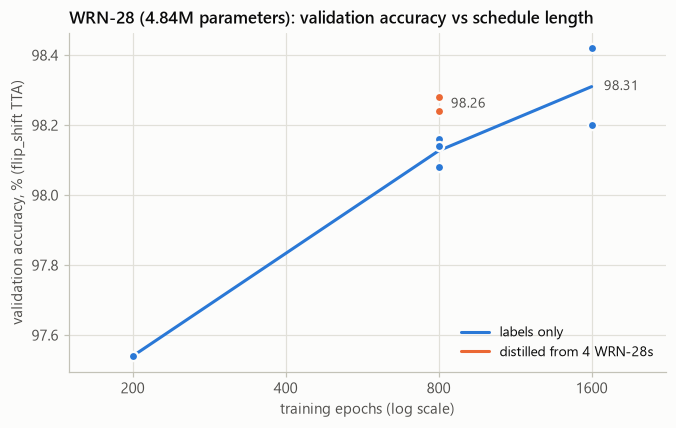

In [4]:
def acc(run, tta="flip_shift"):
    return runs.loc[run, tta] if run in runs.index else np.nan


plain = {200: ["a1_wrn28_cutmix"], 800: ["s3_wrn28_800ep", "s5_wrn28_800ep_seed1", "s6_wrn28_800ep_seed2"],
         1600: ["s4_wrn28_1600ep", "s10_wrn28_1600ep_seed1"]}
distilled = {800: ["k6_kd_ens4_T4_800ep", "k17_kd_ens4_T4_800ep_seed1"], 1600: ["k10_kd_ens4_T4_1600ep"],
             3200: ["k13_kd_ens4_T4_3200ep"]}
fig, ax = plt.subplots(figsize=(7, 4))
for label, groups, color in (("labels only", plain, BLUE), ("distilled from 4 WRN-28s", distilled, ORANGE)):
    xs, means = [], []
    for ep, names in groups.items():
        vals = [acc(r) for r in names if r in runs.index]
        if vals:
            ax.scatter([ep] * len(vals), vals, s=36, color=color, edgecolor=SURFACE, linewidth=1.5, zorder=3)
            xs.append(ep)
            means.append(np.mean(vals))
    ax.plot(xs, means, color=color, label=label, zorder=2)
    ax.annotate(f"{means[-1]:.2f}", (xs[-1], means[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK2)
longest = max(ep for groups in (plain, distilled) for ep, names in groups.items() if any(r in runs.index for r in names))
ax.set_xscale("log", base=2)
ticks = [t for t in (200, 400, 800, 1600, 3200) if t <= longest]
ax.set_xticks(ticks, [str(t) for t in ticks])
ax.set_xlim(150, longest * 1.4)
ax.set_xlabel("training epochs (log scale)")
ax.set_ylabel("validation accuracy, % (flip_shift TTA)")
ax.legend(loc="lower right")
ax.set_title("WRN-28 (4.84M parameters): validation accuracy vs schedule length")
fig.savefig(FIG_DIR / "schedule_length.png")
plt.show()

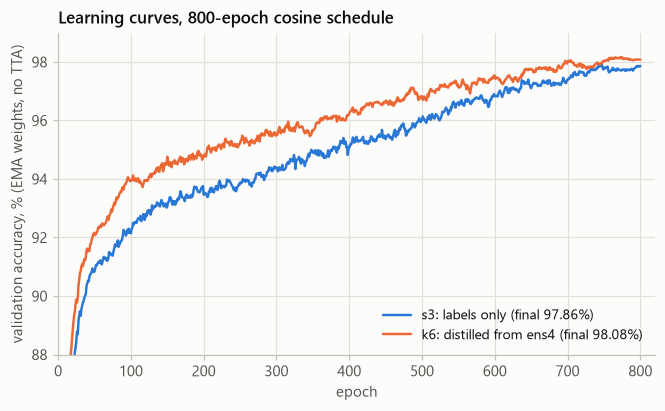

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for run, label, color in (("s3_wrn28_800ep", "s3: labels only", BLUE),
                          ("k6_kd_ens4_T4_800ep", "k6: distilled from ens4", ORANGE)):
    log = pd.read_csv(f"runs/{run}/log.csv")
    ax.plot(log["epoch"], log["val_acc_ema"] * 100, color=color, lw=1.6,
            label=f"{label} (final {log['val_acc_ema'].iloc[-1] * 100:.2f}%)")
ax.set_ylim(88, 99)
ax.set_xlim(0, 820)
ax.set_xlabel("epoch")
ax.set_ylabel("validation accuracy, % (EMA weights, no TTA)")
ax.legend(loc="lower right")
ax.set_title("Learning curves, 800-epoch cosine schedule")
fig.savefig(FIG_DIR / "learning_curves.png")
plt.show()

## Screens and variants

Dot plots: each row is a run; the vertical line marks the reference recipe (a0, s3). Runs more than 1.5%
below it are listed under the chart instead.

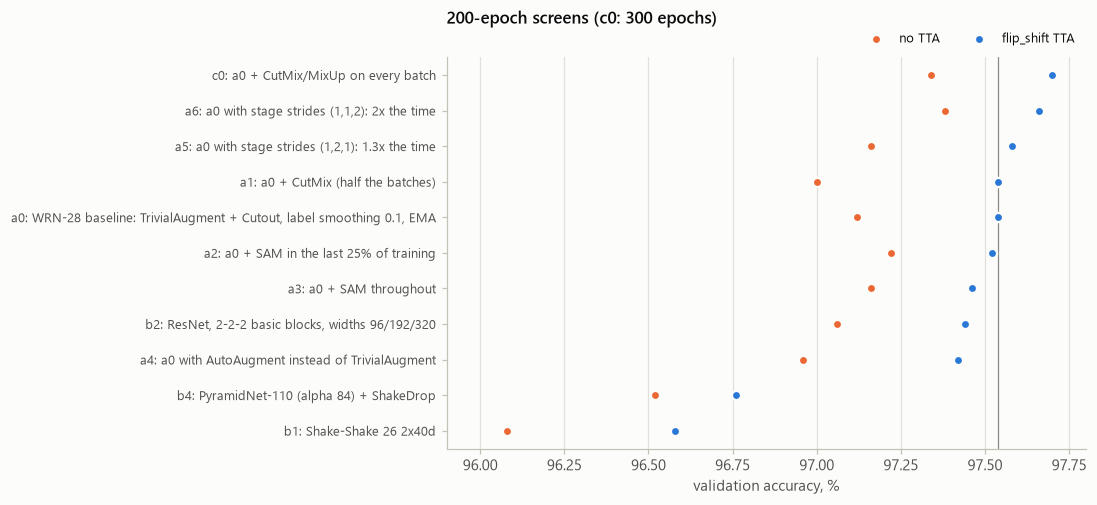

not shown (far below the reference): {'b3_wrn28_shakedrop': 77.24}


In [6]:
def dot_plot(names, reference, title, fname, gap=1.5):
    names = [r for r in names if r in runs.index]
    shown = [r for r in names if runs.loc[r, "flip_shift"] >= runs.loc[reference, "flip_shift"] - gap]
    shown.sort(key=lambda r: runs.loc[r, "flip_shift"])
    fig, ax = plt.subplots(figsize=(7.5, 0.32 * len(shown) + 1.1))
    yy = np.arange(len(shown))
    ax.scatter(runs.loc[shown, "none"], yy, s=36, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, label="no TTA", zorder=3)
    ax.scatter(runs.loc[shown, "flip_shift"], yy, s=36, color=BLUE, edgecolor=SURFACE, linewidth=1.5,
               label="flip_shift TTA", zorder=3)
    ax.axvline(runs.loc[reference, "flip_shift"], color=MUTED, lw=0.8, zorder=1)
    ax.set_yticks(yy, [f"{r.split('_')[0]}: {DESCRIPTIONS.get(r, r)}" for r in shown], fontsize=8.5)
    ax.grid(axis="y", visible=False)
    values = runs.loc[shown, ["none", "flip_shift"]].to_numpy()
    ax.set_xlim(np.floor(values.min() * 10 - 1) / 10, np.ceil(values.max() * 10 + 1) / 10)
    ax.set_xlabel("validation accuracy, %")
    ax.legend(loc="lower right", ncols=2, bbox_to_anchor=(1, 1.0), fontsize=8.5)
    ax.set_title(title, pad=22)
    fig.savefig(FIG_DIR / fname)
    plt.show()
    off = [r for r in names if r not in shown]
    if off:
        print("not shown (far below the reference):", {r: round(float(runs.loc[r, "flip_shift"]), 2) for r in off})


short = [r for r in runs.index if r[0] in "abc" and r[1].isdigit()]
dot_plot(short, "a0_wrn28_ta_200ep", "200-epoch screens (c0: 300 epochs)", "screens_200ep.png")

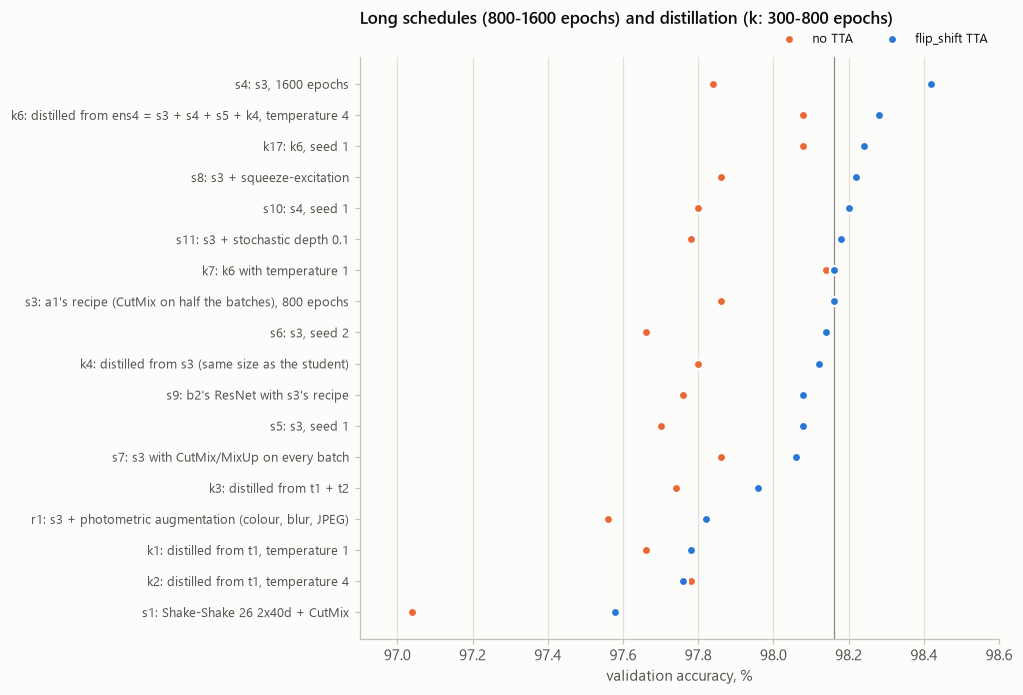

not shown (far below the reference): {'s2_wrn28_shakedrop_800ep': 95.5}


In [7]:
long = [r for r in runs.index if r[0] in "srk" and r[1].isdigit() and not np.isnan(runs.loc[r, "flip_shift"])]
dot_plot(long, "s3_wrn28_800ep", "Long schedules (800-1600 epochs) and distillation (k: 300-800 epochs)",
         "variants_800ep.png")

## Which differences are real?

Two models evaluated on the same 5,000 images are compared with an exact McNemar test on the images exactly
one of them gets right (saved per-image probabilities, flip TTA). Two seeds of the plain 800-epoch WRN-28 disagree
on 60-90 of the 5,000 images, so a gap needs about 17 images (0.35%) to reach p < 0.05; distilled students
disagree with each other on only 40-50 images.

In [8]:
from scipy.stats import binomtest

from resnet5m.data import load_cifar10_train, stratified_split

_, labels = load_cifar10_train("data")
_, val_idx = stratified_split(labels, 5000, seed=0)
y_val = labels[val_idx]
correct = {r: np.load(f"runs/{r}/val_probs.npy").astype(np.float32).argmax(1) == y_val
           for r in runs.index if Path(f"runs/{r}/val_probs.npy").exists()}
PAIRS = [("s5_wrn28_800ep_seed1", "s3_wrn28_800ep", "seed vs seed (labels only)"),
         ("k17_kd_ens4_T4_800ep_seed1", "k6_kd_ens4_T4_800ep", "seed vs seed (distilled)"),
         ("s4_wrn28_1600ep", "s3_wrn28_800ep", "1600 vs 800 epochs"),
         ("k6_kd_ens4_T4_800ep", "s3_wrn28_800ep", "distilled from ens4 vs labels only"),
         ("k4_kd_s3_T4_800ep", "s3_wrn28_800ep", "distilled from one equal model"),
         ("k3_kd_t1t2_T4_800ep", "s3_wrn28_800ep", "distilled from two WRN-28-10s"),
         ("k7_kd_ens4_T1_800ep", "k6_kd_ens4_T4_800ep", "temperature 1 vs 4"),
         ("s8_wrn28_se_800ep", "s3_wrn28_800ep", "squeeze-excitation"),
         ("s11_wrn28_droppath_800ep", "s3_wrn28_800ep", "stochastic depth"),
         ("a6_wrn28_s112_200ep", "a0_wrn28_ta_200ep", "strides (1,1,2), 200 epochs"),
         ("k19_kd_ens4_T4_800ep_s112", "k6_kd_ens4_T4_800ep", "strides (1,1,2), distilled")]
rows = []
for a, b, what in PAIRS:
    if a in correct and b in correct:
        only_a, only_b = int((correct[a] & ~correct[b]).sum()), int((~correct[a] & correct[b]).sum())
        rows.append({"comparison": what, "A": a.split("_")[0], "B": b.split("_")[0],
                     "acc A": correct[a].mean() * 100, "acc B": correct[b].mean() * 100,
                     "only A right": only_a, "only B right": only_b,
                     "p (McNemar)": binomtest(only_a, only_a + only_b, 0.5).pvalue})
display(pd.DataFrame(rows).style.format({"acc A": "{:.2f}", "acc B": "{:.2f}", "p (McNemar)": "{:.3f}"}).hide(axis="index"))

comparison,A,B,acc A,acc B,only A right,only B right,p (McNemar)
seed vs seed (labels only),s5,s3,98.02,98.12,34,39,0.640
seed vs seed (distilled),k17,k6,98.20,98.24,23,25,0.885
1600 vs 800 epochs,s4,s3,98.08,98.12,39,41,0.911
distilled from ens4 vs labels only,k6,s3,98.24,98.12,32,26,0.512
distilled from one equal model,k4,s3,98.10,98.12,31,32,1.000
distilled from two WRN-28-10s,k3,s3,97.92,98.12,29,39,0.275
temperature 1 vs 4,k7,k6,98.14,98.24,19,24,0.542
squeeze-excitation,s8,s3,98.20,98.12,38,34,0.724
stochastic depth,s11,s3,98.12,98.12,39,39,1.000
"strides (1,1,2), 200 epochs",a6,a0,97.52,97.34,57,48,0.435


## Teacher ensembles

The distillation targets are the teachers' averaged probabilities. Ensembles of our 5M models reach 98.4-98.6%
(flip TTA), 0.2-0.4% above the students distilled from them; adding more 5M models barely moves them.

In [9]:
probs = {r: np.load(f"runs/{r}/val_probs.npy").astype(np.float32) for r in correct}
ENSEMBLES = {"ens4 (k6, k8f, k10f)": ["s3_wrn28_800ep", "s4_wrn28_1600ep", "s5_wrn28_800ep_seed1", "k4_kd_s3_T4_800ep"],
             "ens6 (k11f)": ["s3_wrn28_800ep", "s4_wrn28_1600ep", "s5_wrn28_800ep_seed1", "s6_wrn28_800ep_seed2",
                             "s8_wrn28_se_800ep", "s9_resnet222_800ep"],
             "t1 + t2 (k3)": ["t1_wrn28_10_sam", "t2_wrn28_10_sam_cutmix"]}
rows = []
for name, members in ENSEMBLES.items():
    p = sum(probs[m] for m in members) / len(members)
    rows.append({"ensemble": name, "members": len(members),
                 "best member": max(correct[m].mean() for m in members) * 100,
                 "ensemble acc": (p.argmax(1) == y_val).mean() * 100})
display(pd.DataFrame(rows).style.format({"best member": "{:.2f}", "ensemble acc": "{:.2f}"}).hide(axis="index"))
print(f"students distilled from ens4: k6 {correct['k6_kd_ens4_T4_800ep'].mean() * 100:.2f}, "
      f"k17 {correct['k17_kd_ens4_T4_800ep_seed1'].mean() * 100:.2f} (flip TTA)")

ensemble,members,best member,ensemble acc
"ens4 (k6, k8f, k10f)",4,98.12,98.42
ens6 (k11f),6,98.20,98.58
t1 + t2 (k3),2,98.02,98.02


students distilled from ens4: k6 98.24, k17 98.20 (flip TTA)


## Kaggle public leaderboard

The public score uses 1,000 hidden images, so one score has a standard error of about ±0.9% (bars: ±1
standard error). The hidden images are harder than CIFAR-10's (about 90% vs 98% accuracy). Distillation's
validation gain carries over (every distilled model scores above f1), while the differences among the
distilled models are within noise.

run,public score,description,se
f1_wrn28_800ep_full,0.893,s3's recipe on all 50k,0.010
k8f_kd_ens4_T4_800ep_full,0.909,k6's recipe on all 50k,0.009
k11f_kd_ens6_T4_1600ep_full,0.904,"distilled from ens6 = s3 + s4 + s5 + s6 + s8 + s9, 1600 epochs, all 50k",0.009
k14f_kd_ens9_T4_800ep_full,0.898,"distilled from 9 models (ens6 + s7 + s10 + r1), all 50k",0.010
k10f_kd_ens4_T4_1600ep_full,0.899,"k6's recipe, 1600 epochs, all 50k",0.010


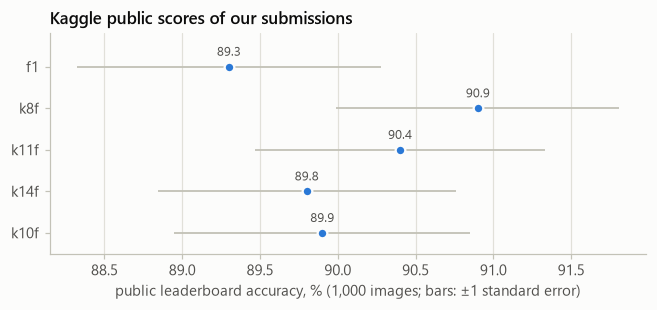

In [10]:
LEADERBOARD = {"f1_wrn28_800ep_full": 0.893, "k8f_kd_ens4_T4_800ep_full": 0.909,
               "k11f_kd_ens6_T4_1600ep_full": 0.904, "k14f_kd_ens9_T4_800ep_full": 0.898,
               "k10f_kd_ens4_T4_1600ep_full": 0.899}
lb = pd.DataFrame({"run": list(LEADERBOARD), "public score": list(LEADERBOARD.values())})
lb["description"] = lb["run"].map(DESCRIPTIONS)
lb["se"] = np.sqrt(lb["public score"] * (1 - lb["public score"]) / 1000)
display(lb.style.format({"public score": "{:.3f}", "se": "{:.3f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(7, 2.6))
yy = np.arange(len(lb))[::-1]
ax.errorbar(lb["public score"] * 100, yy, xerr=lb["se"] * 100, fmt="none", ecolor=AXIS, elinewidth=1.2, zorder=2)
ax.scatter(lb["public score"] * 100, yy, s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
for x, y_ in zip(lb["public score"] * 100, yy):
    ax.annotate(f"{x:.1f}", (x, y_), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8.5, color=INK2)
ax.set_yticks(yy, [r.split("_")[0] for r in lb["run"]])
ax.set_ylim(-0.5, len(lb) - 0.2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("public leaderboard accuracy, % (1,000 images; bars: ±1 standard error)")
ax.set_title("Kaggle public scores of our submissions")
fig.savefig(FIG_DIR / "leaderboard.png")
plt.show()